In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

data_dir = Path("../data")
files = {f.name: f for f in data_dir.rglob("*.csv")}
print(files.keys())

dict_keys(['elliptic_txs_classes.csv', 'elliptic_txs_edgelist.csv', 'elliptic_txs_features.csv'])


In [2]:
feat = pd.read_csv(files["elliptic_txs_features.csv"], header=None)
cls  = pd.read_csv(files["elliptic_txs_classes.csv"])

feat.columns = ["txId", "time_step"] + [f"f{i}" for i in range(feat.shape[1] - 2)]
df = feat.merge(cls, on="txId")

print(df.shape)
print(df["class"].value_counts())

(203769, 168)
class
unknown    157205
2           42019
1            4545
Name: count, dtype: int64


In [3]:
labeled = df[df["class"] != "unknown"]
print("Illicit % of labeled:", round((labeled["class"] == "1").mean() * 100, 2))

Illicit % of labeled: 9.76


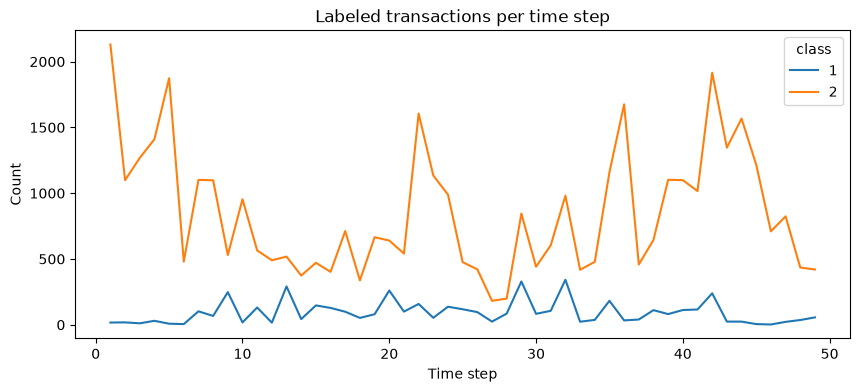

In [4]:
(labeled.groupby(["time_step", "class"]).size()
        .unstack()
        .plot(figsize=(10, 4), title="Labeled transactions per time step"))
plt.xlabel("Time step")
plt.ylabel("Count")
plt.show()